# Credit Risk Scoring

A bank has to decide whether to approve a loan application. Approving someone who later defaults is
expensive; rejecting someone who would have paid back costs a lot less (just the lost interest).
This notebook builds a model that estimates **probability of default** and turns it into an approve/reject
decision that minimises the expected cost to the bank, then converts the model into a simple
**points-based scorecard** like the ones credit teams actually use.

Dataset: German Credit (1,000 applicants, 20 features). 30% of applicants are labelled "bad" credit risk.

The dataset comes with a cost matrix: approving a bad applicant costs **5**, rejecting a good one costs **1**.
That asymmetry drives most of the decisions below.

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (brier_score_loss, confusion_matrix, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
IMG = Path("images"); IMG.mkdir(exist_ok=True)
SEED = 42
COST_FN, COST_FP = 5, 1   # approve a bad applicant / reject a good one

## 1. Load and look at the data

In [2]:
df = pd.read_csv("data/german_credit.csv")
# credit_risk: 1 = good, 0 = bad. I flip it so the positive class is the one we care about (default).
df["default"] = (df["credit_risk"] == 0).astype(int)
df = df.drop(columns="credit_risk")
print(df.shape, "| missing values:", df.isna().sum().sum(), "| default rate: {:.0%}".format(df["default"].mean()))
df.head()

(1000, 21) | missing values: 0 | default rate: 30%


,status,duration,credit_history,purpose,amount,savings,employment_duration,installment_rate,personal_status_sex,other_debtors,...,property,age,other_installment_plans,housing,number_credits,job,people_liable,telephone,foreign_worker,default
0,... < 100 DM,6,critical account/other credits existing,domestic appliances,1169,unknown/no savings account,... >= 7 years,4,male : single,none,...,real estate,67,none,own,2,skilled employee/official,1,yes,yes,0
1,0 <= ... < 200 DM,48,existing credits paid back duly till now,domestic appliances,5951,... < 100 DM,1 <= ... < 4 years,2,female : divorced/separated/married,none,...,real estate,22,none,own,1,skilled employee/official,1,no,yes,1
2,no checking account,12,critical account/other credits existing,retraining,2096,... < 100 DM,4 <= ... < 7 years,2,male : single,none,...,real estate,49,none,own,1,unskilled - resident,2,no,yes,0
3,... < 100 DM,42,existing credits paid back duly till now,radio/television,7882,... < 100 DM,4 <= ... < 7 years,2,male : single,guarantor,...,building society savings agreement/life insurance,45,none,for free,1,skilled employee/official,2,no,yes,0
4,... < 100 DM,24,delay in paying off in the past,car (new),4870,... < 100 DM,1 <= ... < 4 years,3,male : single,none,...,unknown/no property,53,none,for free,2,skilled employee/official,2,no,yes,1


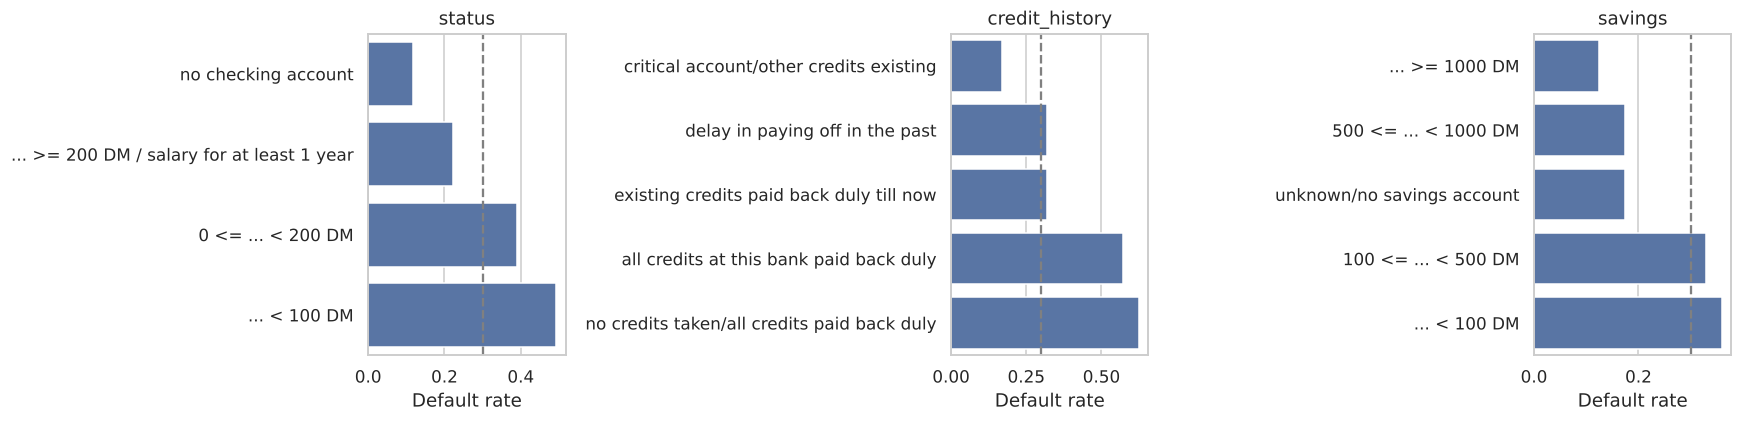

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["status", "credit_history", "savings"]):
    rate = df.groupby(col)["default"].mean().sort_values()
    sns.barplot(x=rate.values, y=rate.index, ax=ax, color="#4C72B0")
    ax.axvline(df["default"].mean(), ls="--", color="grey")
    ax.set(xlabel="Default rate", ylabel="", title=col)
plt.tight_layout(); plt.savefig(IMG / "default_by_category.png", bbox_inches="tight"); plt.show()

- **Checking account status** is the clearest signal. Applicants in the lowest balance band default at 49%,
  while those with no checking account at this bank default at only 12%.
- The **credit history** pattern looks backwards at first: "critical account" applicants default *less* (17%).
  That's a known quirk of this dataset. Those people already have other credits running, which means
  other lenders approved them, so they're already a filtered, lower-risk group.
- More **savings** generally means lower risk.

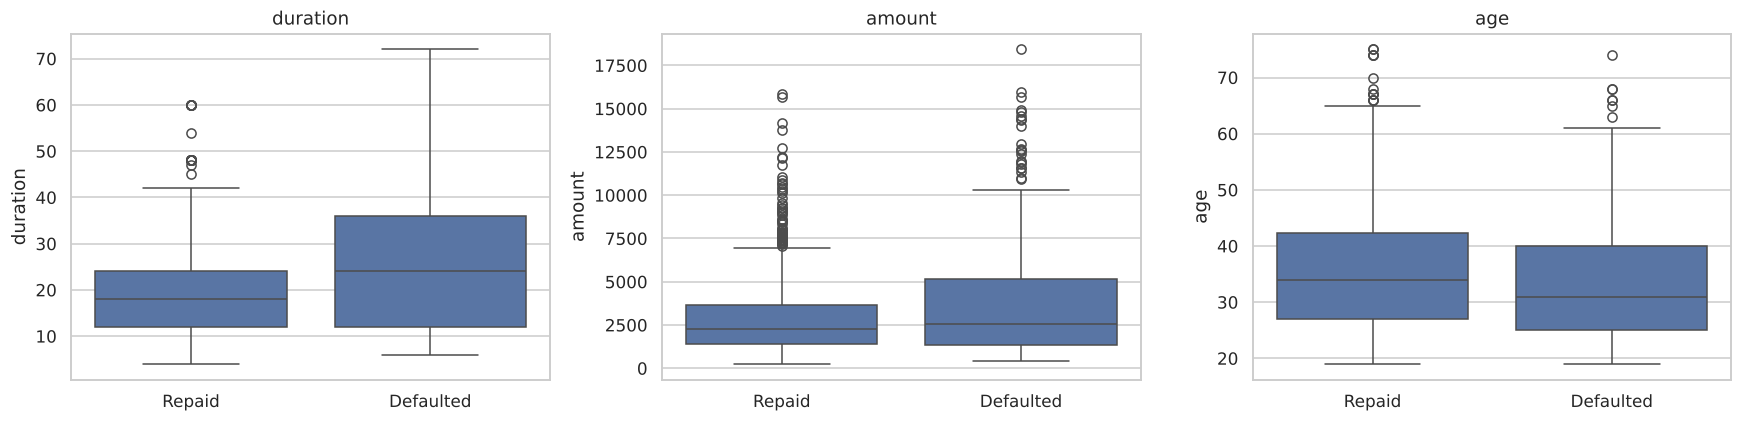

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["duration", "amount", "age"]):
    sns.boxplot(data=df, x="default", y=col, ax=ax)
    ax.set_xticklabels(["Repaid", "Defaulted"]); ax.set_xlabel(""); ax.set_title(col)
plt.tight_layout(); plt.savefig(IMG / "numeric_vs_default.png", bbox_inches="tight"); plt.show()

Longer loans and bigger amounts are riskier, and younger applicants default a bit more often.
Duration and amount are correlated (big loans run longer), so I'll also give the model the
**monthly burden** (amount / duration) as its own feature.

In [5]:
def add_features(d):
    d = d.copy()
    d["monthly_amount"] = d["amount"] / d["duration"]
    d["amount_per_age"] = d["amount"] / d["age"]
    d["young"] = (d["age"] < 25).astype(int)
    return d

df = add_features(df)
X = df.drop(columns="default"); y = df["default"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)
num_cols = X.select_dtypes("number").columns.tolist()
cat_cols = X.select_dtypes("object").columns.tolist()
preprocess = ColumnTransformer([("num", StandardScaler(), num_cols),
                                ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)])
print(f"Train {len(X_train)}  |  Test {len(X_test)}")

Train 750  |  Test 250


## 2. Models

With only 750 training rows I use repeated out-of-fold predictions so every comparison is based on
predictions for data the model hasn't seen. Besides ROC-AUC I track the **expected cost per applicant**
at the best threshold, since that's what the bank actually cares about.

In [6]:
def expected_cost(y_true, proba, t):
    pred = (proba >= t).astype(int)
    fn = ((pred == 0) & (y_true == 1)).sum()
    fp = ((pred == 1) & (y_true == 0)).sum()
    return (COST_FN * fn + COST_FP * fp) / len(y_true)

def best_threshold(y_true, proba):
    grid = np.linspace(0.05, 0.95, 181)
    costs = [expected_cost(y_true, proba, t) for t in grid]
    return grid[int(np.argmin(costs))], min(costs)

models = {
    "Logistic Regression": LogisticRegression(C=0.3, max_iter=2000),
    "Random Forest": RandomForestClassifier(n_estimators=500, min_samples_leaf=3, random_state=SEED, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=2,
                                                    subsample=0.8, random_state=SEED),
}
oof, rows = {}, []
for name, m in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", m)])
    # average out-of-fold predictions over 3 different shuffles to make the threshold search less noisy
    p = np.mean([cross_val_predict(pipe, X_train, y_train, method="predict_proba",
                                   cv=StratifiedKFold(5, shuffle=True, random_state=SEED + r))[:, 1] for r in range(3)], axis=0)
    oof[name] = p
    t, c = best_threshold(y_train.values, p)
    rows.append({"model": name, "ROC-AUC": roc_auc_score(y_train, p), "Brier": brier_score_loss(y_train, p),
                 "best threshold": t, "cost / applicant": c,
                 "cost @ 0.5": expected_cost(y_train.values, p, 0.5)})
comparison = pd.DataFrame(rows).sort_values("cost / applicant").reset_index(drop=True)
baseline_cost = COST_FP * (1 - y_train.mean())   # reject everyone
approve_all = COST_FN * y_train.mean()           # approve everyone
print(f"Reject everyone: {baseline_cost:.3f} per applicant | Approve everyone: {approve_all:.3f}")
comparison.round(3)

Reject everyone: 0.700 per applicant | Approve everyone: 1.500


,model,ROC-AUC,Brier,best threshold,cost / applicant,cost @ 0.5
0,Random Forest,0.791,0.166,0.235,0.513,1.027
1,Gradient Boosting,0.791,0.165,0.165,0.520,0.939
2,Logistic Regression,0.775,0.169,0.110,0.532,0.947


Two things stand out:
1. **The threshold matters more than the model.** At the default 0.5 cut-off every model is *worse* than
   simply rejecting everyone (cost ~0.95 vs 0.70). Moving the cut-off to the cost-optimal value roughly halves
   the cost. With a 5:1 cost ratio, theory says the cut-off should be around 1/(1+5) = 0.17, and the
   data-driven thresholds land close to that (0.11 to 0.24).
2. **The gap between models is small.** Random forest has the lowest cost and logistic regression the highest,
   but they're within about 0.02 per applicant. I use random forest for the approve/reject decision, and come
   back to logistic regression in section 5 to build an explainable scorecard.

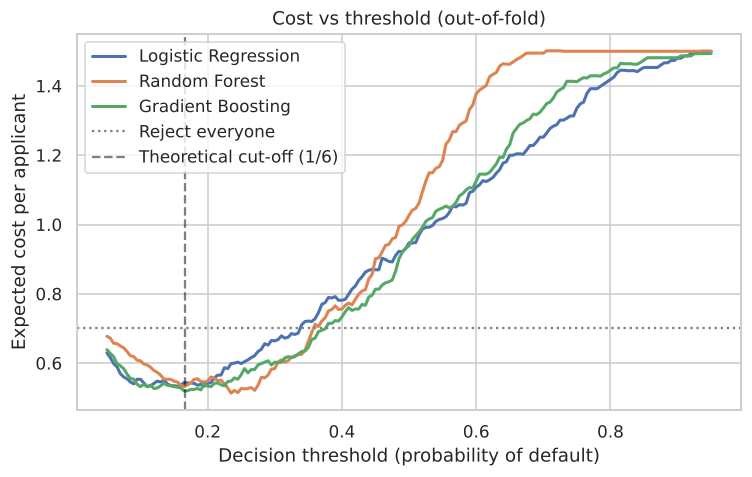

In [7]:
fig, ax = plt.subplots(figsize=(7, 4.5))
grid = np.linspace(0.05, 0.95, 181)
for name, p in oof.items():
    ax.plot(grid, [expected_cost(y_train.values, p, t) for t in grid], label=name, lw=2)
ax.axhline(baseline_cost, ls=":", color="grey", label="Reject everyone")
ax.axvline(1 / 6, ls="--", color="black", alpha=0.5, label="Theoretical cut-off (1/6)")
ax.set(xlabel="Decision threshold (probability of default)", ylabel="Expected cost per applicant",
       title="Cost vs threshold (out-of-fold)")
ax.legend(); plt.tight_layout(); plt.savefig(IMG / "cost_curve.png", bbox_inches="tight"); plt.show()

## 3. Calibration

Since the decision depends on the actual probability values (is it above 0.17?), the probabilities need to
mean what they say. A calibration curve checks that: of applicants given a 30% default risk, about 30% should
actually default.

Final model: Random Forest


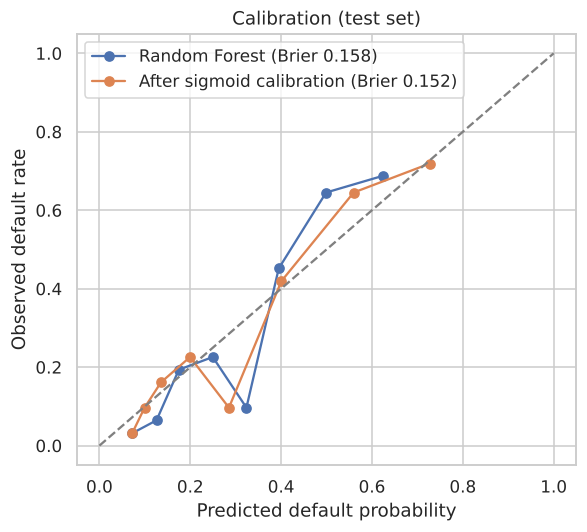

In [8]:
best_name = comparison.loc[0, "model"]
print("Final model:", best_name)
final = Pipeline([("prep", preprocess), ("model", models[best_name])])
final_cal = CalibratedClassifierCV(Pipeline([("prep", preprocess), ("model", models[best_name])]), method="sigmoid", cv=5)
final.fit(X_train, y_train); final_cal.fit(X_train, y_train)
p_raw = final.predict_proba(X_test)[:, 1]; p_cal = final_cal.predict_proba(X_test)[:, 1]

fig, ax = plt.subplots(figsize=(5.5, 5))
for label, p in [(best_name, p_raw), ("After sigmoid calibration", p_cal)]:
    frac, mean_pred = calibration_curve(y_test, p, n_bins=8, strategy="quantile")
    ax.plot(mean_pred, frac, "o-", label=f"{label} (Brier {brier_score_loss(y_test, p):.3f})")
ax.plot([0, 1], [0, 1], "--", color="grey")
ax.set(xlabel="Predicted default probability", ylabel="Observed default rate", title="Calibration (test set)")
ax.legend(); plt.tight_layout(); plt.savefig(IMG / "calibration.png", bbox_inches="tight"); plt.show()

The random forest is roughly calibrated but a bit jumpy in the middle range. Sigmoid calibration smooths it
and slightly improves the Brier score (0.158 to 0.152). For the approve/reject decision it doesn't matter much,
because the threshold was already tuned on the raw scores. If the probabilities were shown to loan officers
as "x% chance of default", I'd use the calibrated version.

## 4. Test set results

In [9]:
threshold, _ = best_threshold(y_train.values, oof[best_name])
proba = p_raw
pred = (proba >= threshold).astype(int)
test_auc = roc_auc_score(y_test, proba)
test_cost = expected_cost(y_test.values, proba, threshold)
cost_05 = expected_cost(y_test.values, proba, 0.5)
gini = 2 * test_auc - 1
fpr, tpr, _ = roc_curve(y_test, proba); ks = float(np.max(tpr - fpr))
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
print(f"Threshold {threshold:.3f}")
print(f"ROC-AUC {test_auc:.3f} | Gini {gini:.3f} | KS {ks:.3f}")
print(f"Expected cost per applicant: {test_cost:.3f} (vs {cost_05:.3f} at 0.5, {COST_FP * (1 - y_test.mean()):.3f} rejecting everyone)")
print(f"Defaulters caught: {tp}/{tp + fn} ({tp / (tp + fn):.0%}) | Good applicants approved: {tn}/{tn + fp} ({tn / (tn + fp):.0%})")
lr_check = Pipeline([("prep", preprocess), ("model", LogisticRegression(C=0.3, max_iter=2000))]).fit(X_train, y_train)
p_lr = lr_check.predict_proba(X_test)[:, 1]
t_lr, _ = best_threshold(y_train.values, oof["Logistic Regression"])
print(f"For comparison, logistic regression on the same test set: AUC {roc_auc_score(y_test, p_lr):.3f}, cost {expected_cost(y_test.values, p_lr, t_lr):.3f}")

Threshold 0.235
ROC-AUC 0.813 | Gini 0.626 | KS 0.537
Expected cost per applicant: 0.524 (vs 0.956 at 0.5, 0.700 rejecting everyone)
Defaulters caught: 65/75 (87%) | Good applicants approved: 94/175 (54%)
For comparison, logistic regression on the same test set: AUC 0.803, cost 0.600


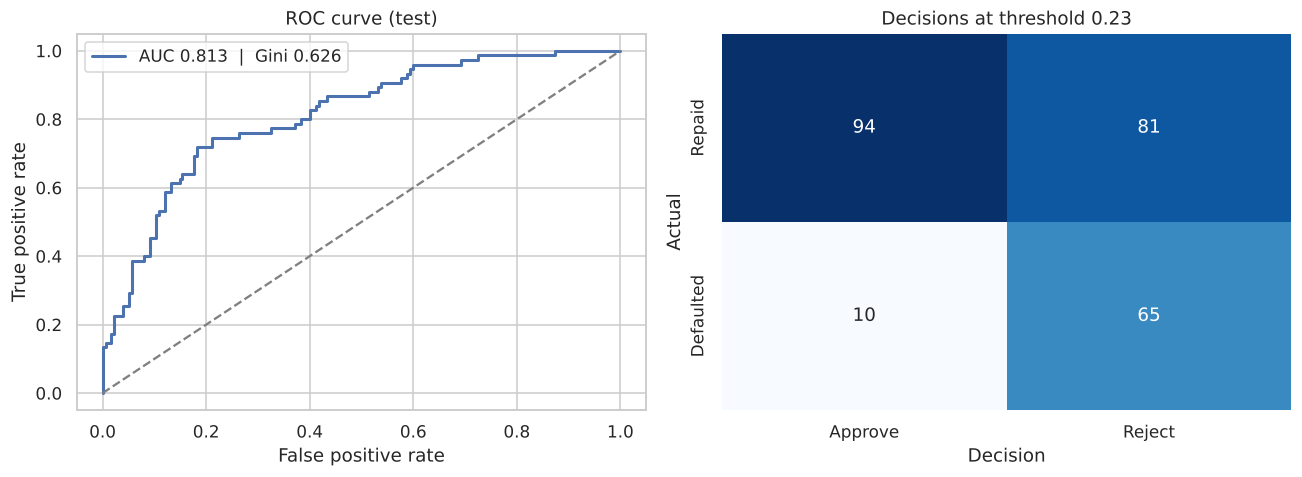

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(fpr, tpr, lw=2, label=f"AUC {test_auc:.3f}  |  Gini {gini:.3f}")
axes[0].plot([0, 1], [0, 1], "--", color="grey")
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curve (test)"); axes[0].legend()
sns.heatmap([[tn, fp], [fn, tp]], annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[1],
            xticklabels=["Approve", "Reject"], yticklabels=["Repaid", "Defaulted"])
axes[1].set(xlabel="Decision", ylabel="Actual", title=f"Decisions at threshold {threshold:.2f}")
plt.tight_layout(); plt.savefig(IMG / "test_results.png", bbox_inches="tight"); plt.show()

## 5. Turning the model into a scorecard

Credit teams usually don't hand out raw probabilities. They use a **points scorecard**: each attribute adds
or removes points, and a higher total score means lower risk. A logistic regression maps onto this directly
because its output is a sum of contributions in log-odds.

Standard scaling used here: **600 points = 50:1 odds of repaying, and every 20 points doubles the odds**
(PDO = 20). To keep it readable I refit the model on a handful of binned features.

In [11]:
sc = X_train.copy(); sc_test = X_test.copy()
bins = {"duration": [0, 12, 24, 36, 100], "amount": [0, 1500, 4000, 8000, 30000], "age": [0, 25, 35, 50, 100]}
for c, b in bins.items():
    sc[c] = pd.cut(sc[c], b).astype(str); sc_test[c] = pd.cut(sc_test[c], b).astype(str)
sc_features = ["status", "credit_history", "savings", "duration", "amount", "purpose", "age", "property"]
enc = OneHotEncoder(handle_unknown="ignore")
Xs = enc.fit_transform(sc[sc_features]); Xs_test = enc.transform(sc_test[sc_features])
lr_sc = LogisticRegression(C=0.3, max_iter=2000).fit(Xs, 1 - y_train)   # model the odds of GOOD
sc_auc = roc_auc_score(y_test, -lr_sc.decision_function(Xs_test))

PDO, BASE, BASE_ODDS = 20, 600, 50
factor = PDO / np.log(2); offset = BASE - factor * np.log(BASE_ODDS)
n_feat = len(sc_features)
names = enc.get_feature_names_out(sc_features)
coef = lr_sc.coef_[0]
card = pd.DataFrame({"feature": [n.split("_", 1)[0] if not n.startswith("credit_history") else "credit_history" for n in names],
                     "attribute": names, "points": factor * coef + (offset + factor * lr_sc.intercept_[0]) / n_feat})
card["feature"] = [next(f for f in sc_features if a.startswith(f + "_")) for a in card["attribute"]]
card["attribute"] = [a[len(f) + 1:] for a, f in zip(card["attribute"], card["feature"])]
card["points"] = card["points"].round().astype(int)
print(f"Scorecard ROC-AUC on test: {sc_auc:.3f} (full model: {test_auc:.3f})")
card[card["feature"].isin(["status", "duration", "savings"])].sort_values(["feature", "points"])

Scorecard ROC-AUC on test: 0.800 (full model: 0.813)


,feature,attribute,points
16,duration,"(24, 36]",56
17,duration,"(36, 100]",58
15,duration,"(12, 24]",60
14,duration,"(0, 12]",80
9,savings,... < 100 DM,47
11,savings,100 <= ... < 500 DM,58
12,savings,500 <= ... < 1000 DM,66
10,savings,... >= 1000 DM,73
13,savings,unknown/no savings account,75
0,status,... < 100 DM,45


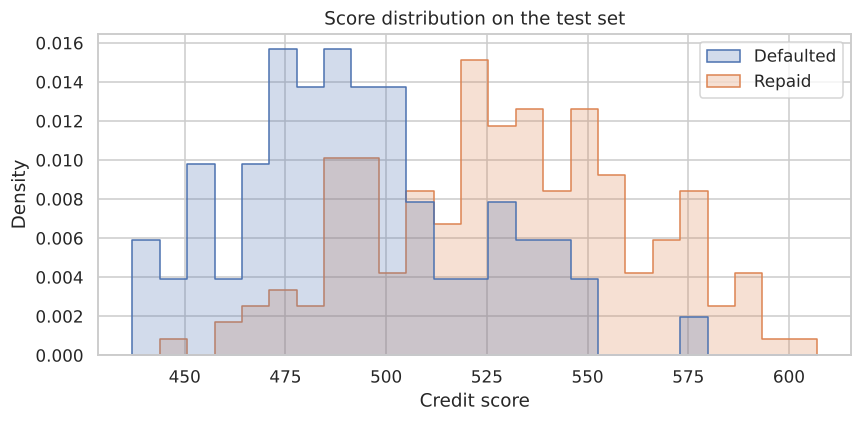

In [12]:
def score(rows):
    m = enc.transform(rows[sc_features]).toarray()
    return (m * card["points"].values).sum(axis=1)

test_scores = score(sc_test)
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(x=test_scores, hue=y_test.map({0: "Repaid", 1: "Defaulted"}).values, bins=25, element="step", stat="density",
             common_norm=False, ax=ax)
ax.set(xlabel="Credit score", title="Score distribution on the test set")
plt.tight_layout(); plt.savefig(IMG / "score_distribution.png", bbox_inches="tight"); plt.show()

The scorecard keeps most of the full model's ranking power while being something a loan officer can add up
by hand, and every point can be traced back to a specific attribute.

In [13]:
Path("results").mkdir(exist_ok=True)
results = {
    "oof_comparison": comparison.round(4).to_dict(orient="records"),
    "threshold": round(float(threshold), 3),
    "final_model": best_name, "test_roc_auc": round(float(test_auc), 4), "test_gini": round(float(gini), 4), "test_ks": round(ks, 4),
    "test_cost_per_applicant": round(float(test_cost), 4), "test_cost_at_0.5": round(float(cost_05), 4),
    "test_cost_reject_all": round(float(COST_FP * (1 - y_test.mean())), 4),
    "defaulters_caught": f"{tp}/{tp + fn}", "good_approved": f"{tn}/{tn + fp}",
    "scorecard_auc": round(float(sc_auc), 4),
}
json.dump(results, open("results/metrics.json", "w"), indent=2)
card.to_csv("results/scorecard.csv", index=False)
results

{'oof_comparison': [{'model': 'Random Forest',
   'ROC-AUC': 0.791,
   'Brier': 0.1665,
   'best threshold': 0.235,
   'cost / applicant': 0.5133,
   'cost @ 0.5': 1.0267},
  {'model': 'Gradient Boosting',
   'ROC-AUC': 0.7915,
   'Brier': 0.1646,
   'best threshold': 0.165,
   'cost / applicant': 0.52,
   'cost @ 0.5': 0.9387},
  {'model': 'Logistic Regression',
   'ROC-AUC': 0.7746,
   'Brier': 0.1691,
   'best threshold': 0.11,
   'cost / applicant': 0.532,
   'cost @ 0.5': 0.9467}],
 'threshold': 0.235,
 'final_model': 'Random Forest',
 'test_roc_auc': 0.8131,
 'test_gini': 0.6262,
 'test_ks': 0.5371,
 'test_cost_per_applicant': 0.524,
 'test_cost_at_0.5': 0.956,
 'test_cost_reject_all': 0.7,
 'defaulters_caught': '65/75',
 'good_approved': '94/175',
 'scorecard_auc': 0.8004}

## Takeaways

- **Optimising the threshold for the real cost ratio mattered far more than the choice of model.** On the test
  set the random forest costs 0.52 per applicant at its tuned threshold, versus 0.96 at 0.5 and 0.70 for
  rejecting everyone. It catches 87% of defaulters while still approving over half of the good applicants.
- Random forest, gradient boosting and logistic regression were within a couple of points of each other on
  this small dataset.
- The points scorecard (test AUC 0.80 vs 0.81 for the random forest) gives almost the same ranking quality
  in a format credit teams can audit.

**Caveats:** 1,000 rows is small, so the test numbers have wide error bars. The data also includes
`personal_status_sex` and `foreign_worker`. I left them in to match the original benchmark, but a real lending
model would have to drop or carefully audit attributes like these for fairness and regulatory reasons.